This work was created in collaboration with Johannes Schäfers, Benedikt Schneider, Ferdi Nilius and Steffen Pablo Krieg

# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [5]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt

from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [6]:
def confusion_matrix(y_true, y_pred):
    y_true , y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true=y_true, y_pred=y_pred)
    n = tp + fn + fp + tn

    accuracy = (tp + tn) / n if (n != 0) else 0
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) != 0 else 0

    return accuracy, precision, recall, f1 

def roc_curve(y_true, scores):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    order = np.argsort(-scores)
    y_true_sort, scores_sort = y_true[order], scores[order]
    tp, fp = np.cumsum(y_true_sort == 1), np.cumsum(y_true_sort == 0)
    last = np.r_[True, scores_sort[1:] != scores_sort[:-1]]
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, scores_sort[last]]
    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    return np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), sk_confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), roc_auc_score(y_small, s_small))

(np.int64(5), np.int64(1), np.int64(1), np.int64(13)) [[13  1]
 [ 1  5]]
0.8571428571428571 0.7797619047619048 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


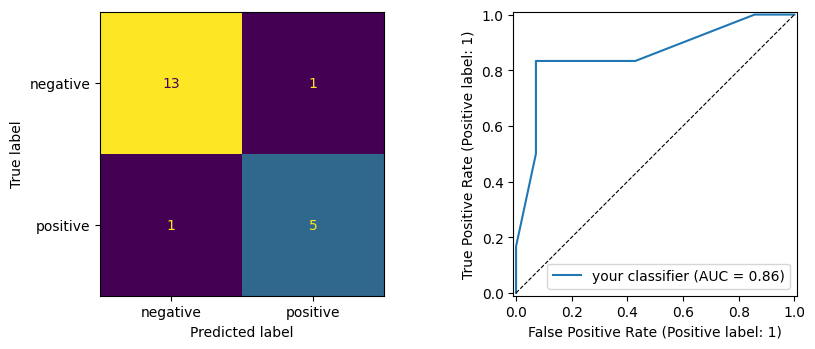

In [7]:
y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

In [ ]:
######
# Dataset download: code adapted from a suggestion by Claude (Anthropic,
# model Claude Opus 5.5), accessed 2026-10-21. Used to fetch mnist.npz
# when it is not present locally.
import urllib.request, os

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
if not os.path.exists("mnist.npz"):
    urllib.request.urlretrieve(url, "mnist.npz")
#####

d = 7                              # your digit
with np.load("mnist.npz") as data:            # see Project 2 for where to get it
    x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
    x_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
    y_train = (data["y_train"] == d).astype(float)
    y_test = (data["y_test"] == d).astype(float)

n_sub = 10000                               # training subset, full training set is 60,000 images; smaller for faster runs
x_tr, y_tr = x_train[:n_sub], y_train[:n_sub]


In [ ]:
# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def sigmoid_der(z):
    s = sigmoid(z)
    return s * (1 - s)


def softmax(z):
    e_z = jnp.exp(z - jnp.max(z, axis=-1, keepdims=True))
    return e_z / jnp.sum(e_z, axis=-1, keepdims=True)


def mse(predict, target):
    return jnp.mean((predict - target) ** 2)


def create_layers_batch(network_input_size, layer_output_sizes):
    """
    Create randomly initialised layers for the batched convention.

    Parameters
    ----------
    network_input_size : int
        Number of input features.
    layer_output_sizes : list of int
        Number of nodes in each layer.

    Returns
    -------
    layers : list of (W, b)
        W has shape (inputs, outputs), b has shape (outputs,).

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted create_layers from exercise 5 by transposing the weight shape to (inputs, outputs).
    Modifications/verification: Shapes checked when running the gradient check at the end of this cell.
    """
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)   # (inputs, outputs)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    """
    Feed a batch forward through the network, z = a @ W + b.

    Parameters
    ----------
    inputs : array, shape (n_samples, n_features)
        Samples in the rows.
    layers : list of (W, b)
    activation_funcs : list of callables, one per layer

    Returns
    -------
    a : array, shape (n_samples, n_outputs)
        Output of the last layer.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Rewrote feed_forward from exercise 5 for samples in the rows.
    Modifications/verification: Used by cost_batch, which jax.grad differentiates in the check at the end of this cell.
    """
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = a @ W + b
        a = activation_func(z)
    return a


def cost_batch(layers, inputs, activation_funcs, targets):
    """
    Mean squared error of the network output over the whole batch.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Batched version of cost from exercise 5.
    Modifications/verification: Differentiated with jax.grad as the reference gradient.
    """
    predict = feed_forward_batch(inputs, layers, activation_funcs)
    return mse(predict, targets)


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    """
    Batched forward pass that also saves the layer inputs and the zs,
    which backpropagation needs.

    Returns
    -------
    layer_inputs : list of arrays, layer_inputs[i] has shape (n_samples, inputs of layer i)
    zs : list of arrays, zs[i] has shape (n_samples, outputs of layer i)
    a : array, network output

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Batched version of feed_forward_saver from exercise 5.
    Modifications/verification: Used by backpropagation_batch, verified in the check at the end of this cell.
    """
    layer_inputs = []
    zs = []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a


def mse_der_batch(predict, targets):
    """
    Derivative of mse with respect to predict for a batch.

    mse takes the mean over all n_samples * n_outputs elements, so the
    derivative is 2 (predict - targets) / predict.size.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Pointed out that mse_der divides by len(predict), which is only the number of samples for a 2D batch, and wrote this version.
    Modifications/verification: Verified against jax.grad of cost_batch (check at the end of this cell) and, by Claude,
    against central finite differences; all gradients agree.
    """
    return 2 * (predict - targets) / predict.size


def cross_entropy(predict, target):
    return jnp.sum(-target * jnp.log(predict))


def cost_cross_entropy(layers, input, activation_funcs, target):
    predict = feed_forward_batch(input, layers, activation_funcs)
    return cross_entropy(predict, target)


def backpropagation_batch_cross_entropy(
    inputs, layers, activation_funcs, targets, activation_ders, cost_der=cross_entropy
):

    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    
    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # Last layer: dC_da can be computed directly from the cost
            dC_dz = predict - targets
        else:
            # Propagate the error back: samples stay in the rows
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T
            dC_dz = dC_da * activation_der(z)            # (n_samples, outputs)
        
        dC_dW = layer_input.T @ dC_dz                # (inputs, outputs), summed over samples
        dC_db = np.sum(dC_dz, axis=0)                # (outputs,), summed over samples

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads


def accuracy(predictions, targets):
    one_hot_predictions = np.zeros(predictions.shape)

    for i, prediction in enumerate(predictions):
        one_hot_predictions[i, np.argmax(prediction)] = 1
    return accuracy_score(one_hot_predictions, targets)


def make_batches(n, batch_size, rng):
    idx = rng.permutation(n)
    return [idx[i:i + batch_size] for i in range(0, n, batch_size)]


def step_length(t, t0, t1):
    return t0 / (t + t1)


def gradient(theta, X, y, lam=0.0):
    n = len(y)
    return (2.0 / n) * X.T @ (X @ theta - y) + 2.0 * lam * theta


def optimiser_step(method, theta, g, state, t, gamma, beta=0.9, rho=0.99,
                   beta1=0.9, beta2=0.999, eps=1e-8):
    if method == "plain":
        return theta - gamma * g, state
    if method == "momentum":
        v = beta * state.get("v", 0.0) + gamma * g
        state["v"] = v
        return theta - v, state
    if method == "adagrad":
        r = state.get("r", 0.0) + g * g
        state["r"] = r
        return theta - gamma * g / (np.sqrt(r) + eps), state
    if method == "rmsprop":
        r = rho * state.get("r", 0.0) + (1.0 - rho) * g * g
        state["r"] = r
        return theta - gamma * g / (np.sqrt(r) + eps), state
    if method == "adam":
        m = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g
        r = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g
        state["m"], state["r"] = m, r
        m_hat = m / (1.0 - beta1**t)
        r_hat = r / (1.0 - beta2**t)
        return theta - gamma * m_hat / (np.sqrt(r_hat) + eps), state
    raise ValueError(f"unknown method {method}")


def train_network(
    inputs, layers, activation_funcs, targets, activation_ders, epochs=100,
    method="momentum", batch_size=10, gamma=0.01, schedule=None, seed=2026,
    X_test=None, Y_test=None, **kw
):
    """
    Train the network with minibatch gradient descent, using optimiser_step
    on every W and b, and record the cost and accuracy after each epoch.

    Parameters
    ----------
    inputs, targets : training data, targets one-hot
    layers : list of (W, b), the initial layers (not modified)
    activation_funcs, activation_ders : lists, one entry per layer
    epochs : int, number of passes over the training data
    method : "plain", "momentum", "adagrad", "rmsprop" or "adam"
    batch_size : int, use len(inputs) for full-batch gradient descent
    gamma : float, learning rate
    schedule : (t0, t1) for a decaying learning rate, or None
    X_test, Y_test : optional test data for the test accuracy
    **kw : passed on to optimiser_step (beta, rho, beta1, beta2, eps)

    Returns
    -------
    layers : list of (W, b), the trained layers
    history : dict of arrays "cost", "train_accuracy", "test_accuracy", one entry per epoch
    
    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted my Project 1 sgd function from a single parameter vector theta to the
    list of (W, b) pairs, with a separate optimiser state for each W and b.
    Modifications/verification: Uses my own make_batches, step_length and optimiser_step
    unchanged; checked by the decreasing training cost and the test accuracy below.
    """
    rng = np.random.default_rng(seed)                     # created once: new batch order every epoch
    layers = [(W.copy(), b.copy()) for W, b in layers]    # don't overwrite the initial layers
    states = [({}, {}) for _ in layers]                   # optimiser state per W and b, kept across epochs
    n = inputs.shape[0]
    t = 0                                                 # step counter, kept across epochs (Adam bias correction)
    history = {"cost": [], "train_accuracy": [], "test_accuracy": []}

    for epoch in range(epochs):
        for batch in make_batches(n, batch_size, rng):
            t += 1
            grads = backpropagation_batch_cross_entropy(
                inputs[batch], layers, activation_funcs, targets[batch], activation_ders
            )
            g_t = gamma if schedule is None else step_length(t, *schedule)
            new_layers = []
            for (W, b), (dW, db), (state_W, state_b) in zip(layers, grads, states):
                W, _ = optimiser_step(method, W, dW, state_W, t, g_t, **kw)
                b, _ = optimiser_step(method, b, db, state_b, t, g_t, **kw)
                new_layers.append((W, b))
            layers = new_layers

        # bookkeeping once per epoch
        history["cost"].append(cost_cross_entropy(layers, inputs, activation_funcs, targets))
        history["train_accuracy"].append(accuracy(feed_forward_batch(inputs, layers, activation_funcs), targets))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(feed_forward_batch(X_test, layers, activation_funcs), Y_test))

    return layers, {key: np.array(value) for key, value in history.items()}


def backpropagation_batch(
    inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der_batch
):
    """
    Gradient of the cost with respect to all weights and biases, for a batch.

    Parameters
    ----------
    inputs : array, shape (n_samples, n_features)
    layers : list of (W, b), W of shape (inputs, outputs)
    activation_funcs, activation_ders : lists of callables, one per layer
    targets : array, shape (n_samples, n_outputs)
    cost_der : callable, derivative of the cost w.r.t. the network output

    Returns
    -------
    layer_grads : list of (dC_dW, dC_db), same shapes as layers

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Rewrote backpropagation from exercise 5 for batches: error propagated with dC_dz @ W.T, parameter gradients summed over the samples.
    Modifications/verification: Verified against jax.grad of cost_batch (check at the end of this cell) and, by Claude,
    against central finite differences; all gradients agree.
    """
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # Last layer: dC_da can be computed directly from the cost
            dC_da = cost_der(predict, targets)
        else:
            # Propagate the error back: samples stay in the rows
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T

        dC_dz = dC_da * activation_der(z)            # (n_samples, outputs)
        dC_dW = layer_input.T @ dC_dz                # (inputs, outputs), summed over samples
        dC_db = np.sum(dC_dz, axis=0)                # (outputs,), summed over samples

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads


def binary_accuracy(predictions, targets):
    """
    Accuracy of a single sigmoid output, with the threshold 0.5.

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Pointed out that accuracy() uses argmax, which is always 0 for one output
    column, and wrote this threshold version for the binary case.
    Modifications/verification: Not run by Claude; to be checked against
    sklearn.metrics.accuracy_score.
    """
    return float(np.mean((np.asarray(predictions) > 0.5) == np.asarray(targets)))


def train_network(
    inputs, layers, activation_funcs, targets, activation_ders, epochs=100,
    method="momentum", batch_size=10, gamma=0.01, schedule=None, seed=2026,
    X_test=None, Y_test=None, backprop_func=backpropagation_batch_cross_entropy,
    cost_func=cost_cross_entropy, accuracy_func=accuracy, **kw
):
    """
    Train the network with minibatch gradient descent, using optimiser_step
    on every W and b, and record the cost and accuracy after each epoch.

    Parameters
    ----------
    inputs, targets : training data; targets one-hot (multiclass) or shape (n, 1) (binary)
    layers : list of (W, b), the initial layers (not modified)
    activation_funcs, activation_ders : lists, one entry per layer
    epochs : int, number of passes over the training data
    method : "plain", "momentum", "adagrad", "rmsprop" or "adam"
    batch_size : int, use len(inputs) for full-batch gradient descent
    gamma : float, learning rate
    schedule : (t0, t1) for a decaying learning rate, or None
    X_test, Y_test : optional test data for the test accuracy
    cost_func : cost recorded in the history, signature (layers, inputs, activation_funcs, targets);
        should match the cost that backprop_func differentiates
    accuracy_func : accuracy recorded in the history, signature (predictions, targets)
    **kw : passed on to optimiser_step (beta, rho, beta1, beta2, eps)

    Returns
    -------
    layers : list of (W, b), the trained layers
    history : dict of arrays "cost", "train_accuracy", "test_accuracy", one entry per epoch

    LLM-assisted
    ------------
    Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
    Role: Adapted my Project 1 sgd function from a single parameter vector theta to the
    list of (W, b) pairs, with a separate optimiser state for each W and b.
    Added cost_func and accuracy_func (2026-10-21), so that the binary classifier
    records its MSE training cost and the threshold accuracy instead of the
    multiclass cross-entropy and argmax accuracy.
    Modifications/verification: Uses my own make_batches, step_length and optimiser_step
    unchanged; checked by the decreasing training cost and the test accuracy below.
    The cost_func/accuracy_func change was not run by Claude.
    """
    rng = np.random.default_rng(seed)                     # created once: new batch order every epoch
    layers = [(W.copy(), b.copy()) for W, b in layers]    # don't overwrite the initial layers
    states = [({}, {}) for _ in layers]                   # optimiser state per W and b, kept across epochs
    n = inputs.shape[0]
    t = 0                                                 # step counter, kept across epochs (Adam bias correction)
    history = {"cost": [], "train_accuracy": [], "test_accuracy": []}

    for epoch in range(epochs):
        for batch in make_batches(n, batch_size, rng):
            t += 1
            grads = backprop_func(
                inputs[batch], layers, activation_funcs, targets[batch], activation_ders
            )
            g_t = gamma if schedule is None else step_length(t, *schedule)
            new_layers = []
            for (W, b), (dW, db), (state_W, state_b) in zip(layers, grads, states):
                W, _ = optimiser_step(method, W, dW, state_W, t, g_t, **kw)
                b, _ = optimiser_step(method, b, db, state_b, t, g_t, **kw)
                new_layers.append((W, b))
            layers = new_layers

        # bookkeeping once per epoch
        history["cost"].append(float(cost_func(layers, inputs, activation_funcs, targets)))
        history["train_accuracy"].append(accuracy_func(feed_forward_batch(inputs, layers, activation_funcs), targets))
        if X_test is not None:
            history["test_accuracy"].append(accuracy_func(feed_forward_batch(X_test, layers, activation_funcs), Y_test))

    return layers, {key: np.array(value) for key, value in history.items()}

Logistic regression test accuracy: 0.9789
accuracy 0.9789 ± 0.0014  precision 0.9445  recall 0.8444 ± 0.0113  F1 0.8916


              precision    recall  f1-score   support

     'not-7'       0.98      0.99      0.99      8972
         '7'       0.94      0.84      0.89      1028

    accuracy                           0.98     10000
   macro avg       0.96      0.92      0.94     10000
weighted avg       0.98      0.98      0.98     10000

AUC 0.9879


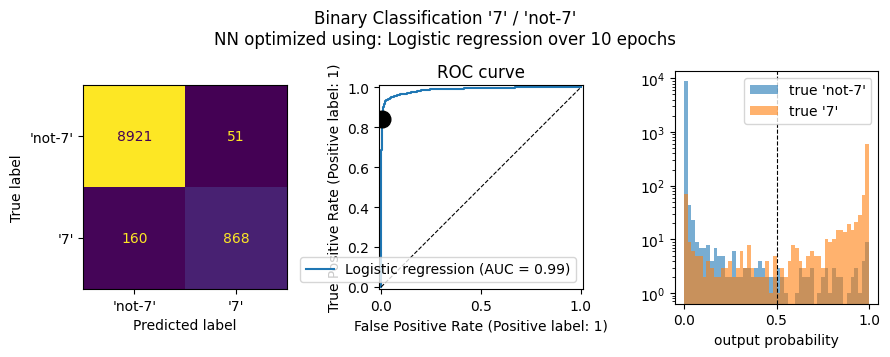

SGD with momentum  test accuracy: 0.9789
accuracy 0.9789 ± 0.0014  precision 0.9445  recall 0.8444 ± 0.0113  F1 0.8916


              precision    recall  f1-score   support

     'not-7'       0.98      0.99      0.99      8972
         '7'       0.94      0.84      0.89      1028

    accuracy                           0.98     10000
   macro avg       0.96      0.92      0.94     10000
weighted avg       0.98      0.98      0.98     10000

AUC 0.9879


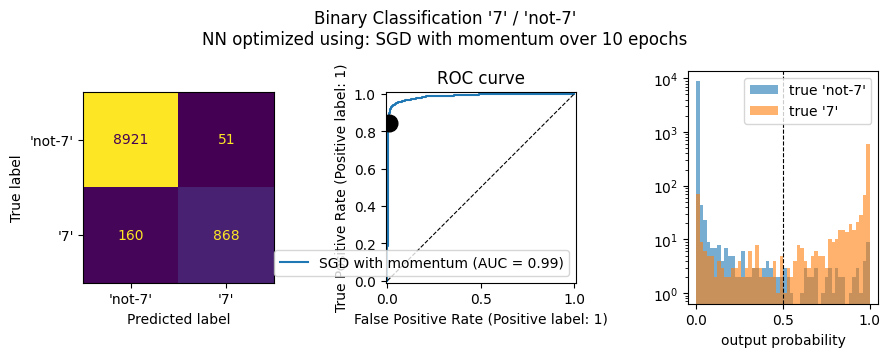

SGD with Adam      test accuracy: 0.9799
accuracy 0.9799 ± 0.0014  precision 0.9451  recall 0.8541 ± 0.0110  F1 0.8973


              precision    recall  f1-score   support

     'not-7'       0.98      0.99      0.99      8972
         '7'       0.95      0.85      0.90      1028

    accuracy                           0.98     10000
   macro avg       0.96      0.92      0.94     10000
weighted avg       0.98      0.98      0.98     10000

AUC 0.9883


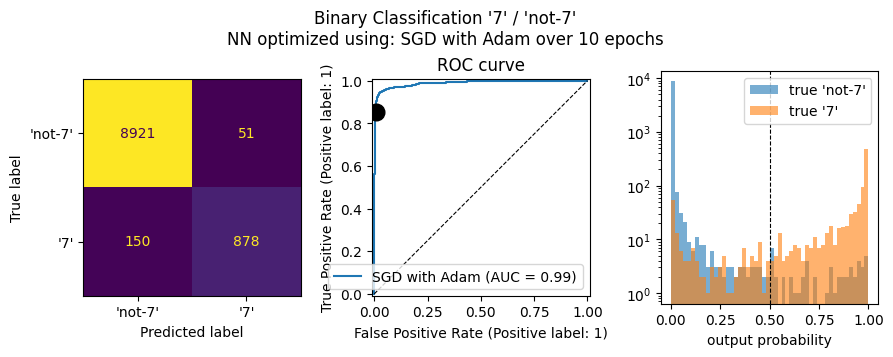

In [17]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)

######
# LLM-assisted
# ------------
# Tool: Claude (Claude Opus 5.5, claude.ai, October 2026)
# Role: Reviewed this cell on 2026-10-21 and fixed:
#   - X_train -> x_train in the runs dict (NameError)
#   - the loop now passes each run's settings (**settings); before, all runs were identical
#   - p_test (sigmoid probabilities) for the ROC/AUC, y_pred (threshold 0.5) for the
#     confusion matrix and the other classification metrics
#   - binary_accuracy and the MSE cost (cost_batch) recorded in the training history
#   - scaled initial weights (He: std sqrt(2 / inputs)) and zero biases, with a fixed seed
#   - training on a 10,000-image subset and epochs set per run, to keep the runtime manageable
# Modifications/verification: Not run by Claude; results to be checked by me.
#####


activation_funcs = [ReLU, sigmoid]
activation_ders = [ReLU_der, sigmoid_der]

rng_init = np.random.default_rng(2026)
layers = [
    (rng_init.standard_normal(W.shape) * np.sqrt(2.0 / W.shape[0]), np.zeros_like(b))
    for W, b in create_layers_batch(x_tr.shape[1], [32, 1])    # network architecture
]

runs = {
    "Logistic regression": dict(method="momentum",    gamma=0.01,  batch_size=10,        epochs=10),
    "SGD with momentum": dict(method="momentum", gamma=0.01,  batch_size=10,        epochs=10),
    "SGD with Adam":     dict(method="adam",     gamma=0.01,  batch_size=10,        epochs=10),
}

for name, settings in runs.items():

    if name == "Logistic regression":
        layers = [
            (rng_init.standard_normal(W.shape) * np.sqrt(2.0 / W.shape[0]), np.zeros_like(b))
            for W, b in create_layers_batch(x_tr.shape[1], [1])    # network architecture
        ]

        activation_funcs = [sigmoid]
        activation_ders = [sigmoid_der]

        trained_layers, history = train_network(
            x_tr,
            layers,
            activation_funcs,
            y_tr[:, None],
            activation_ders=activation_ders,
            schedule=None,
            X_test=x_test,
            Y_test=y_test[:, None],
            backprop_func=backpropagation_batch_cross_entropy,
            cost_func=cost_cross_entropy,
            accuracy_func=binary_accuracy,
            **settings,
        )

    else:   
        trained_layers, history = train_network(
            x_tr,
            layers,
            activation_funcs,
            y_tr[:, None],
            activation_ders,
            schedule=None,
            X_test=x_test,
            Y_test=y_test[:, None],
            backprop_func=backpropagation_batch_cross_entropy,
            cost_func=cost_cross_entropy,
            accuracy_func=binary_accuracy,
            **settings,
        )

    p_test = np.asarray(feed_forward_batch(x_test, trained_layers, activation_funcs))[:, 0]   # probabilities
    y_pred = (p_test > 0.5).astype(int)                                                       # classes

    print(f"{name:18s} test accuracy: {history['test_accuracy'][-1]:.4f}")

    cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = cm.ravel()
    # print(cm)

    accuracy, precision, recall, f1 = classification_report(y_test, y_pred)

    accuracy_uncertainty = np.sqrt(accuracy * (1 - accuracy) / len(y_test))   # n is the number of test samples
    recall_uncertainty = np.sqrt(recall * (1 - recall) / (tp + fn))   # n = TP + FN, the number of positive samples in the test set

    print(f"accuracy {accuracy:.4f} ± {accuracy_uncertainty:.4f}  precision {precision:.4f}  "
          f"recall {recall:.4f} ± {recall_uncertainty:.4f}  F1 {f1:.4f}\n\n")


    print(sk_classification_report(y_test, y_pred, target_names=[f"'not-{d}'", f"'{d}'"], zero_division=0))

    fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
    print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

    fig, ax = plt.subplots(1, 3, figsize=(9, 3.6))

    ConfusionMatrixDisplay(cm, display_labels=[f"'not-{d}'", f"'{d}'"]).plot(ax=ax[0], colorbar=False)
    RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name=name)

    ax[1].plot(fpr[np.where(thresholds >= 0.5)][-1], tpr[np.where(thresholds >= 0.5)][-1], "o", markersize=12, color="black", lw=1.5, label=f"50% threshold")   # 50% threshold point
    
    ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)   # diagonal line for random classifier
    
    ax[1].set_title(f"ROC curve")


    bins = np.linspace(0, 1, 51)
    ax[2].hist(p_test[y_test == 0], bins=bins, alpha=0.6, label=f"true 'not-{d}'")
    ax[2].hist(p_test[y_test == 1], bins=bins, alpha=0.6, label=f"true '{d}'")
    ax[2].axvline(0.5, color="k", ls="--", lw=0.8)       # decision threshold
    ax[2].set_yscale("log")
    ax[2].set_xlabel("output probability")

    fig.suptitle(f"Binary Classification '{d}' / 'not-{d}'\nNN optimized using: " + name + f" over {settings['epochs']} epochs")
    plt.tight_layout(); plt.legend();plt.show()



**b)** The accuracies hide the imbalance in the data set (10% are 7 vs. 90$ not-7) and hide if inaccuracies come from false positive or false negative classifications. Relative to the majority rule, which always predicts “not-0” and has an error rate of 10%, the logistic regression  and the Adam classifier both remove 78.9%, where the fraction removed is defined as 1 − err_classifier / err_majority.

_I used Claude (Anthropic, model Claude Opus 5.5) on 21 October 2026 to clarify the meaning of “fraction of the remaining error relative to the majority rule” and to draft the wording of the corresponding sentence in the report. The numerical values were computed and inserted by me._

**c)**  
The false positive errors are the "not-7" values to the right of the threshold in the histogram, where the false negative are the "7" values to the left. The AUC curve determines the classifier power over all the ROC curve, where as the confusion matrix only looks at a single operating point at 0.5.

**d)** As the accuracies and recall values agree with one another inside the uncertainty ranges, the changes are all insignifikant.

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
# multiclass classifier

x_train_multi, y_train_multi = x_train[:n_sub], y_train[:n_sub]

activation_funcs = [ReLU, ReLU, softmax]
activation_ders = [ReLU_der, ReLU_der, None]   # softmax derivative is handled in the backpropagation function

rng_init = np.random.default_rng(2026)
layers = [
    (rng_init.standard_normal(W.shape) * np.sqrt(2.0 / W.shape[0]), np.zeros_like(b))
    for W, b in create_layers_batch(x_tr.shape[1], [100, 10])    # network architecture
]

runs = {
    "SGD with momentum": dict(method="momentum", gamma=0.01,  batch_size=10,        epochs=10),
    "SGD with Adam":     dict(method="adam",     gamma=0.01,  batch_size=10,        epochs=10),
    "full-batch GD":     dict(method="plain",    gamma=0.001, batch_size=len(x_tr), epochs=1000),
}

for name, settings in runs.items():
    trained_layers, history = train_network(
        x_tr,
        layers,
        activation_funcs,
        y_tr[:, None],
        activation_ders,
        schedule=None,
        X_test=x_test,
        Y_test=y_test[:, None],
        backprop_func=backpropagation_batch_cross_entropy,
        cost_func=cost_cross_entropy,
        accuracy_func=accuracy,
        **settings,
    )

    # plot the multiclass confusion matrix for each run
    y_pred_multi = np.argmax(feed_forward_batch(x_test, trained_layers, activation_funcs), axis=1)

    cm_multi = sk_confusion_matrix(y_test, y_pred_multi)
    print(cm_multi)
    
    fig, ax = plt.subplots(1, 1, figsize=(9, 3.6))

    ConfusionMatrixDisplay(cm, display_labels=[i for i in range(10)]).plot(ax=ax[0], colorbar=False)

    fig.suptitle(f"Multiclass Classification \nNN optimized using: " + name + f" over {settings['epochs']} epochs")
    plt.tight_layout(); plt.legend();plt.show()

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …